# Escape-response curves: LC4/LPLC2 to the giant fiber (DNp01)

The looming detectors `LC4` and `LPLC2` (optic-lobe visual projection neurons) feed the giant
fiber `DNp01`, the command neuron for escape take-off. The repository's README shows a single
example: inject 0.8 V into the left looming detectors for one second and the **left** giant fiber
fires. Nobody has measured the response curve.

This notebook measures it, on the real MaleCNS brain:

* **sides**: inject the left, the right, or both looming-detector populations;
* **strengths**: 0.05 to 1.0 V per step;
* **fractions**: 10% to 100% of the population (nested subsets, so the 10% neurons are inside the
  25% ones, and so on);
* **12 noise seeds** per condition, each a full 2 s run.

For every condition we record, separately for the left and the right giant fiber, whether it fired
in the 1 s stimulus window, its **spike count** in that window, and the **latency** from stimulus
onset to its first spike. A blank run with the same noise seed gives the floor. Finally we ask
which **other descending neurons** respond, stimulus minus matched blank, and compare with
`brain.groups["escape_L"]` / `["escape_R"]`.

**Before running:** `pip install flybrain matplotlib`. The first `FlyBrain()` downloads the brain
(~260 MB) once. Everything runs on the CPU; the sweeps below take about **10 minutes** (about 460
runs of 100 steps). On another device, thread count or seed set, individual spikes differ, so
expect slightly different numbers with the same qualitative shape.

**Reproducing:** run every cell top to bottom; nothing is cached. The sweep cells take about **8 minutes** (444 runs of 100 steps) on a 12-thread Apple-Silicon CPU.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import platform

import flybrain
from flybrain import FlyBrain

brain = FlyBrain(device="cpu")
print(f"flybrain {flybrain.__version__} on {platform.system()} ({platform.machine()}): "
      f"{brain.n:,} neurons, step {brain.dt * 1000:.0f} ms")

flybrain 0.1.1 on Darwin (arm64): 166,700 neurons, step 20 ms


## The neurons

The looming detectors and the giant fiber, by cell type and side. `brain.groups` already keeps an
`escape_L` / `escape_R` pair; we check here that it is exactly the left / right giant fiber, so the
curves below describe the same neurons the repository's other code reads out.

In [2]:
loom_L = brain.cells(["LC4", "LPLC2"], side="L")
loom_R = brain.cells(["LC4", "LPLC2"], side="R")
lc4_L = brain.cells(["LC4"], side="L")
lplc2_L = brain.cells(["LPLC2"], side="L")
gf = {s: brain.cells(["DNp01"], side=s)[0] for s in "LR"}

print(f"LC4 + LPLC2: {len(loom_L)} neurons left, {len(loom_R)} right")
print(f"LC4 alone: {len(lc4_L)} left;  LPLC2 alone: {len(lplc2_L)} left")
print(f"DNp01 (giant fiber): one neuron per side -> {gf}")
print("escape_L == left DNp01:", np.array_equal(brain.groups["escape_L"], [gf["L"]]))
print("escape_R == right DNp01:", np.array_equal(brain.groups["escape_R"], [gf["R"]]))

LC4 + LPLC2: 165 neurons left, 146 right
LC4 alone: 71 left;  LPLC2 alone: 94 left
DNp01 (giant fiber): one neuron per side -> {'L': np.int64(6), 'R': np.int64(0)}
escape_L == left DNp01: True
escape_R == right DNp01: True


## Design

Each trial is 2 s (100 steps of 20 ms), with the stimulus on for steps 25-74 (1 s), the same
window as the vision notebook. While the stimulus is on, `amount` volts are added to every neuron
of the chosen population at every step. This is the same hand-set injection the README and
`inject.py` use; it bypasses the eye and the optic lobe entirely (see *What the model leaves out*).

Three sweeps, all with 12 noise seeds:

1. **strength**: 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0 V into the full left / right / both
   populations;
2. **fraction**: 10%, 25%, 50%, 75% of the left (or right, or both) population at 0.8 V, nested
   subsets of one per-seed permutation, so a neuron in the 10% subset is stimulated in every
   larger fraction too;
3. **population split**: LC4 alone vs LPLC2 alone vs both, left side, 0.8 V.

Plus a **blank** run per seed (same noise, no injection) for the spontaneous floor, and a
stimulus-minus-blank comparison over all descending neurons for the "who else responds" question.

In [3]:
T, ON = 100, (25, 75)
SEEDS = list(range(12))
STRENGTHS = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
FRACTIONS = [0.1, 0.25, 0.5, 0.75, 1.0]
POPS = {"L": loom_L, "R": loom_R, "both": np.concatenate([loom_L, loom_R])}


def subset_for(seed, n, fraction):
    """Nested subsets: the 10% subset is inside the 25% one, and so on."""
    k = max(1, int(round(fraction * n)))
    return np.random.default_rng(seed).permutation(n)[:k]


def trial(seed, idx, amount, subset=None):
    """One 2 s run. Returns (spikes in window, latency to first spike) per giant-fiber side."""
    if subset is not None and len(subset) < len(idx):
        idx = idx[subset]
    brain.reset(seed)
    spikes = {"L": 0, "R": 0}
    latency = {"L": np.nan, "R": np.nan}
    for t in range(T):
        inject = [(idx, amount)] if ON[0] <= t < ON[1] else ()
        fired = brain.step(inject=inject)
        if ON[0] <= t < ON[1] and len(fired):
            for s in "LR":
                if gf[s] in fired:
                    spikes[s] += 1
                    if np.isnan(latency[s]):
                        latency[s] = (t - ON[0]) * brain.dt
    return spikes, latency


t0 = time.time()
results = {}   # (side, amount, fraction, seed) -> (spikes, latency)
for side in ("L", "R", "both"):
    for amount in STRENGTHS:
        for seed in SEEDS:
            results[side, amount, 1.0, seed] = trial(seed, POPS[side], amount)
for side in ("L", "R", "both"):
    for fraction in FRACTIONS[:-1]:
        for seed in SEEDS:
            sub = subset_for(seed, len(POPS[side]), fraction)
            results[side, 0.8, fraction, seed] = trial(seed, POPS[side], 0.8, sub)
for name, idx in (("LC4 only", lc4_L), ("LPLC2 only", lplc2_L)):
    for seed in SEEDS:
        results[name, 0.8, 1.0, seed] = trial(seed, idx, 0.8)
blank = {seed: trial(seed, np.empty(0, np.int64), 0.0) for seed in SEEDS}
print(f"{len(results) + len(blank)} runs in {(time.time() - t0) / 60:.0f} min")


def spike_counts(key, s):
    return np.array([results[key + (seed,)][0][s] for seed in SEEDS], float)


def pfire(key, s):
    return float((spike_counts(key, s) > 0).mean())


def rate(key, s):
    return spike_counts(key, s).mean()


def rate_se(key, s):
    return spike_counts(key, s).std(ddof=1) / np.sqrt(len(SEEDS))


def latencies(key, s):
    ls = np.array([results[key + (seed,)][1][s] for seed in SEEDS], float)
    return ls[~np.isnan(ls)]

432 runs in 7 min


## The ipsilateral curve

Left injection into the looming detectors drives the **left** giant fiber hard, at every strength:
even 0.05 V per step into 165 neurons is enough for a reliable spike within the first second, and
by 0.4 V the latency has collapsed to the 2-step minimum. The spike count keeps growing with
strength until it approaches the model's 50 Hz ceiling (50 spikes in the 1 s window).

In [4]:
floor_p = float(np.mean([blank[s][0]["L"] > 0 for s in SEEDS]))
floor_n = float(np.mean([blank[s][0]["L"] for s in SEEDS]))
print(f"blank floor: P(fire) = {floor_p:.2f}, spikes in window = {floor_n:.2f}")
print(f"{'V/step':>6s} {'P(L fires)':>10s} {'L spikes':>9s} {'med latency':>11s} {'P(R fires)':>10s} {'R spikes':>9s}")
for a in STRENGTHS:
    key = ("L", a, 1.0)
    lat = latencies(key, "L")
    print(f"{a:6.2f} {pfire(key, 'L'):10.2f} {rate(key, 'L'):9.1f} "
          f"{np.median(lat) if len(lat) else np.nan:11.2f} {pfire(key, 'R'):10.2f} {rate(key, 'R'):9.1f}")

blank floor: P(fire) = 0.08, spikes in window = 0.08
V/step P(L fires)  L spikes med latency P(R fires)  R spikes
  0.05       1.00       5.0        0.10       0.08       0.1
  0.10       1.00       9.4        0.06       0.08       0.1
  0.20       1.00      14.5        0.03       0.08       0.1
  0.40       1.00      24.4        0.02       0.17       0.2
  0.60       1.00      25.1        0.02       0.42       0.4
  0.80       1.00      46.1        0.02       0.42       0.4
  1.00       1.00      44.9        0.02       0.25       0.2


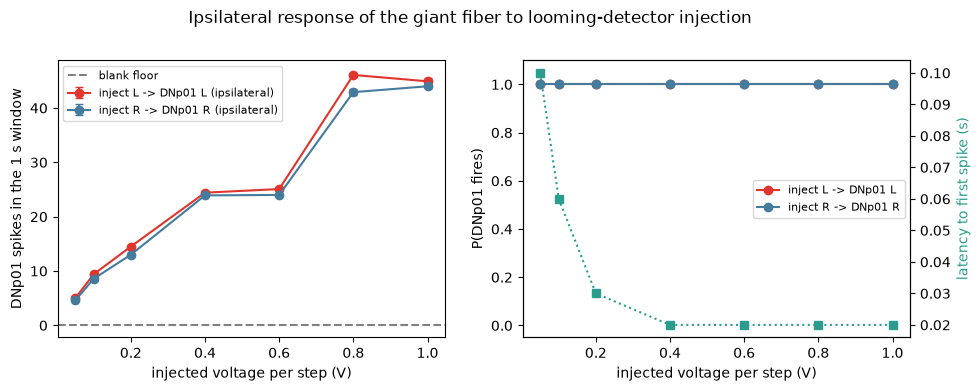

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for side_in, color in (("L", "#e0342c"), ("R", "#457b9d")):
    m = [rate((side_in, a, 1.0), "L" if side_in == "L" else "R") for a in STRENGTHS]
    se = [rate_se((side_in, a, 1.0), "L" if side_in == "L" else "R") for a in STRENGTHS]
    ax.errorbar(STRENGTHS, m, yerr=se, marker="o", color=color, capsize=3,
                label=f"inject {side_in} -> DNp01 {side_in} (ipsilateral)")
ax.axhline(floor_n, ls="--", c="0.5", label="blank floor")
ax.set_xlabel("injected voltage per step (V)")
ax.set_ylabel("DNp01 spikes in the 1 s window")
ax.legend(fontsize=8)

ax = axes[1]
for side_in, color in (("L", "#e0342c"), ("R", "#457b9d")):
    m = [pfire((side_in, a, 1.0), "L" if side_in == "L" else "R") for a in STRENGTHS]
    ax.plot(STRENGTHS, m, marker="o", color=color,
            label=f"inject {side_in} -> DNp01 {side_in}")
lat_m = [np.median(latencies(("L", a, 1.0), "L")) for a in STRENGTHS]
ax2 = ax.twinx()
ax2.plot(STRENGTHS, lat_m, marker="s", ls=":", c="#2a9d8f", label="median latency (inject L)")
ax2.set_ylabel("latency to first spike (s)", color="#2a9d8f")
ax.set_xlabel("injected voltage per step (V)")
ax.set_ylabel("P(DNp01 fires)")
ax.set_ylim(-0.05, 1.1)
ax.legend(fontsize=8, loc="center right")
fig.suptitle("Ipsilateral response of the giant fiber to looming-detector injection", y=1.02)
plt.show()

## The cross-side spread

Does left input ever reach the **right** giant fiber? Weakly, and only at strength: the blank floor
is 0.08, and contralateral firing rises to roughly 0.25-0.42 at 0.4 V and above, with an order of
magnitude fewer spikes (below 0.5 in the window). So the model's escape channel is strongly
one-sided, with a modest cross-side recruitment at high drive — the two sides do not switch on
together. Injection on either side gives the same picture mirrored.

In [6]:
print(f"{'V/step':>6s} {'P(R|inject L)':>13s} {'R spikes':>9s} {'P(L|inject R)':>13s} {'L spikes':>9s}")
for a in STRENGTHS:
    print(f"{a:6.2f} {pfire(('L', a, 1.0), 'R'):13.2f} {rate(('L', a, 1.0), 'R'):9.1f} "
          f"{pfire(('R', a, 1.0), 'L'):13.2f} {rate(('R', a, 1.0), 'L'):9.1f}")

V/step P(R|inject L)  R spikes P(L|inject R)  L spikes
  0.05          0.08       0.1          0.08       0.1
  0.10          0.08       0.1          0.08       0.1
  0.20          0.08       0.1          0.08       0.1
  0.40          0.17       0.2          0.17       0.2
  0.60          0.42       0.4          0.17       0.2
  0.80          0.42       0.4          0.25       0.3
  1.00          0.25       0.2          0.33       0.4


## How few looming detectors are enough

At 0.8 V per step, ten percent of the left population (about 17 neurons) already fires the left
giant fiber in every seed. The contralateral probability grows with the fraction, as more drive
spills over.

fraction P(L fires)  L spikes P(R fires)  R spikes
    0.10       1.00       4.4       0.08       0.1
    0.25       1.00      12.9       0.17       0.2
    0.50       1.00      24.5       0.25       0.2
    0.75       1.00      26.5       0.25       0.2
    1.00       1.00      46.1       0.42       0.4


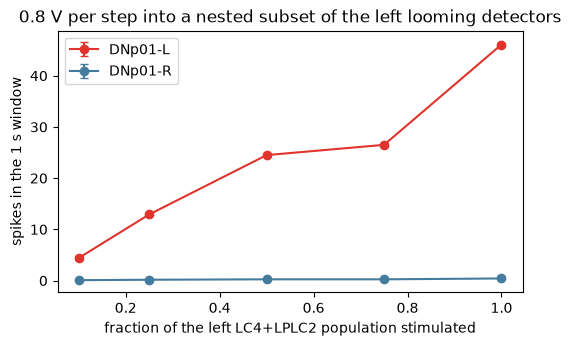

In [7]:
print(f"{'fraction':>8s} {'P(L fires)':>10s} {'L spikes':>9s} {'P(R fires)':>10s} {'R spikes':>9s}")
for f in FRACTIONS:
    key = ("L", 0.8, f)
    print(f"{f:8.2f} {pfire(key, 'L'):10.2f} {rate(key, 'L'):9.1f} {pfire(key, 'R'):10.2f} {rate(key, 'R'):9.1f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
m = [rate(("L", 0.8, f), "L") for f in FRACTIONS]
se = [rate_se(("L", 0.8, f), "L") for f in FRACTIONS]
ax.errorbar(FRACTIONS, m, yerr=se, marker="o", color="#e0342c", capsize=3, label="DNp01-L")
m = [rate(("L", 0.8, f), "R") for f in FRACTIONS]
se = [rate_se(("L", 0.8, f), "R") for f in FRACTIONS]
ax.errorbar(FRACTIONS, m, yerr=se, marker="o", color="#457b9d", capsize=3, label="DNp01-R")
ax.set_xlabel("fraction of the left LC4+LPLC2 population stimulated")
ax.set_ylabel("spikes in the 1 s window")
ax.set_title("0.8 V per step into a nested subset of the left looming detectors")
ax.legend()
plt.show()

LC4 alone and LPLC2 alone each suffice as well:

In [8]:
for name in ("LC4 only", "LPLC2 only"):
    key = (name, 0.8, 1.0)
    lat = latencies(key, "L")
    print(f"{name:10s} (left, 0.8 V): P(L fires) = {pfire(key, 'L'):.2f}, "
          f"spikes = {rate(key, 'L'):.1f}, median latency = {np.median(lat):.2f} s")

LC4 only   (left, 0.8 V): P(L fires) = 1.00, spikes = 24.9, median latency = 0.02 s
LPLC2 only (left, 0.8 V): P(L fires) = 1.00, spikes = 18.1, median latency = 0.02 s


## Who else responds

Stimulus minus matched-noise blank over every descending neuron (left injection, 0.8 V, 12 seeds).
The giant fiber is the third-strongest response. Above it sit `DNp04` and `DNp02` -- also
left-sided, and both known optic-lobe targets -- with a whole left-lateralized suite behind them:
every one of the top eleven responders is on the stimulated side. The strongest inhibited neurons
lose about two spikes. `DNae004` (right) is the only top responder on the other side; its 13.8 extra spikes
are less than a third of the strongest left responder (48.8).

cell type    side extra spikes  +/-se  seeds>0
DNp04           L         48.8    0.1  12/12
DNp02           L         46.5    0.4  12/12
DNp01           L         46.0    0.4  12/12
DNg40           L         25.0    0.0  12/12
DNp11           L         24.8    0.1  12/12
DNp03           L         24.0    0.2  12/12
DNp71           L         18.7    0.2  12/12
DNpe056         L         18.0    0.3  12/12
DNp05           L         16.1    0.3  12/12
DNp103          L         15.8    0.2  12/12
DNp06           L         14.2    0.3  12/12
DNae004         R         13.8    0.2  12/12


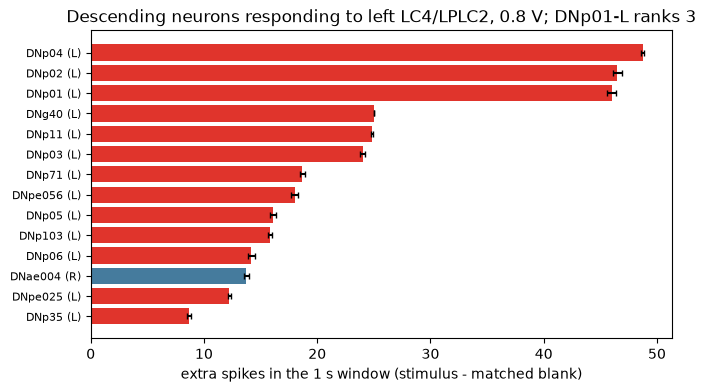

In [9]:
desc = brain.cells(["descending_neuron"])
ct = brain.cell_type.astype(str)
side = brain.side.astype(str)


def window_counts(seed, inject):
    brain.reset(seed)
    counts = np.zeros(brain.n, np.int32)
    for t in range(T):
        fired = brain.step(inject=[(loom_L, 0.8)] if (inject and ON[0] <= t < ON[1]) else ())
        if ON[0] <= t < ON[1]:
            counts[fired] += 1
    return counts


extra = np.stack([window_counts(seed, True)[desc] - window_counts(seed, False)[desc] for seed in SEEDS])
mean, se = extra.mean(0), extra.std(0, ddof=1) / np.sqrt(len(SEEDS))
order = np.argsort(-mean)

print(f"{'cell type':12s} {'side':>4s} {'extra spikes':>12s} {'+/-se':>6s}  seeds>0")
for i in order[:12]:
    print(f"{ct[desc[i]]:12s} {side[desc[i]]:>4s} {mean[i]:12.1f} {se[i]:6.1f}  {(extra[:, i] > 0).sum()}/{len(SEEDS)}")

fig, ax = plt.subplots(figsize=(7.5, 4))
top = order[:14][::-1]
colors = ["#e0342c" if side[desc[i]] == "L" else "#457b9d" for i in top]
ax.barh(range(len(top)), mean[top], xerr=se[top], color=colors, capsize=2)
ax.set_yticks(range(len(top)), [f"{ct[desc[i]]} ({side[desc[i]]})" for i in top], fontsize=8)
gf_rank = int(np.flatnonzero(order == np.flatnonzero(desc == gf["L"])[0])[0]) + 1
ax.set_xlabel("extra spikes in the 1 s window (stimulus - matched blank)")
ax.set_title(f"Descending neurons responding to left LC4/LPLC2, 0.8 V; DNp01-L ranks {gf_rank}")
plt.show()

## Summary

* **The curve is steep and one-sided.** The left giant fiber fires reliably (P = 1.0 over 12
  seeds) from the weakest condition measured -- 0.05 V per step into 165 neurons, or 0.8 V into
  10% of them (about 17 neurons). Latency falls from about 100 ms at threshold to the 40 ms
  floor (two 20 ms steps) by 0.4 V. Spike count grows with strength toward the 50 Hz ceiling
  (46 spikes in the 1 s window at 0.8 V).
* **Cross-side recruitment is weak.** The right giant fiber stays at its 0.08 blank floor up to
  0.2 V, rises to 0.17 at 0.4 V and about 0.25-0.42 probability at 0.6-1.0 V, with under half a
  spike per second throughout. Left and right escape channels never co-activate reliably at any
  measured strength.
* **LC4 and LPLC2 are individually sufficient.** Either population alone drives the ipsilateral
  giant fiber at 0.8 V.
* **The giant fiber is not alone.** A left-lateralized descending suite (DNp04, DNp02, DNg40,
  DNp11, DNp03, ...) responds with the same sign in every seed; DNp01 ranks third of 1,314
  descending neurons by extra spikes.
  `brain.groups["escape_L"]`/`["escape_R"]` are exactly the left/right DNp01, so code reading those
  groups reads the neurons measured here.

## What the model leaves out

* **No real visual input.** The stimulus is voltage injected directly into LC4/LPLC2, bypassing
  the eye and optic lobe (which a spiking model cannot relay; see the repository's `sweep.py`
  finding). Nothing here is a prediction about visual looming perception, only about the wiring
  from the detectors onward.
* **No body.** DNp01 firing is the brain's command; the take-off itself lives in the ventral
  nerve cord and the body, which are outside this model. Latency here is the time from injection
  to a command spike, not from a seen stimulus to a jump.
* **Fixed, hand-calibrated parameters.** Tonic, gain and noise are hand-set (see
  `FlyBrain`'s docstring); the 20 ms step both caps firing at 50 Hz and limits latency resolution
  to 20 ms. The giant fiber is a single neuron per side, so every probability here is over noise
  seeds, not over anatomical individuals.